# Fuzzy ensemble: EVA-02 + MobileNetV3

Combines **EVA-02 (transformer)** with **MobileNetV3 (CNN)**. 


Two fuzzy methods are applied to this combination:
- **Fuzzy rank-based ensemble**
- **Choquet fuzzy integral** (Sugeno fuzzy measure, trust levels tuned on the validation set)



In [1]:
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import brentq
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)

IN_DIR = "/kaggle/working/all_probs"
OUT_DIR = os.path.join(IN_DIR, "fuzzy_eva02_mobilenetv3")
os.makedirs(OUT_DIR, exist_ok=True)

# Kaggle: gather the saved .npy files from every place they can be:
#   - /kaggle/input   (datasets / notebook outputs you added with "Add Input")
#   - /kaggle/working (files created earlier in THIS session, e.g. by a training notebook)
import glob, shutil
sources = glob.glob("/kaggle/input/**/*.npy", recursive=True) + \
          [p for p in glob.glob("/kaggle/working/**/*.npy", recursive=True) if not p.startswith(IN_DIR)]
for path in sources:
    shutil.copy(path, IN_DIR)

# the label files must be identical everywhere, otherwise the splits differed
for lbl in ["val_labels.npy", "test_labels.npy"]:
    arrs = [np.load(p) for p in sources if os.path.basename(p) == lbl]
    print(f"{lbl}: found {len(arrs)} copies, all identical = {all(np.array_equal(arrs[0], a) for a in arrs)}" if arrs else f"{lbl}: not found")
print("Files collected:", sorted(f for f in os.listdir(IN_DIR) if f.endswith(".npy")))

MODELS = ["eva02", "mobilenetv3"]
COMBOS = {
    "EVA02 + MobileNetV3": ["eva02", "mobilenetv3"],
}
CLASS_NAMES = ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']

val_labels.npy: found 2 copies, all identical = True
test_labels.npy: found 2 copies, all identical = True
Files collected: ['eva02_test_probs.npy', 'eva02_val_probs.npy', 'mobilenetv3_test_probs.npy', 'mobilenetv3_val_probs.npy', 'test_labels.npy', 'val_labels.npy']


In [2]:
for fn in ["val_labels.npy", "test_labels.npy"]:
    print(("OK       " if os.path.exists(os.path.join(IN_DIR, fn)) else "MISSING  ") + fn)

available = []
for m in MODELS:
    ok = all(os.path.exists(os.path.join(IN_DIR, f"{m}_{s}_probs.npy")) for s in ("val", "test"))
    print(("OK       " if ok else "MISSING  ") + f"{m} (val + test probabilities)")
    if ok:
        available.append(m)

assert "eva02" in available, "EVA-02 files are missing"
combos_ok = {n: ms for n, ms in COMBOS.items() if all(m in available for m in ms)}
print("\nExperiments that will run:", list(combos_ok))
assert combos_ok, "Some model files are MISSING (see above). Train that model first."

OK       val_labels.npy
OK       test_labels.npy
OK       eva02 (val + test probabilities)
OK       mobilenetv3 (val + test probabilities)

Experiments that will run: ['EVA02 + MobileNetV3']


In [3]:
val_labels = np.load(os.path.join(IN_DIR, "val_labels.npy"))
test_labels = np.load(os.path.join(IN_DIR, "test_labels.npy"))
Pv = {m: np.load(os.path.join(IN_DIR, f"{m}_val_probs.npy")) for m in available}
Pt = {m: np.load(os.path.join(IN_DIR, f"{m}_test_probs.npy")) for m in available}

for m in available:
    assert len(Pv[m]) == len(val_labels) and len(Pt[m]) == len(test_labels), f"{m}: size mismatch"

print(f"Val images: {len(val_labels)} | Test images: {len(test_labels)}\n")
for m in available:
    print(f"{m:12s} val acc = {accuracy_score(val_labels, Pv[m].argmax(1))*100:.2f}% | "
          f"test acc = {accuracy_score(test_labels, Pt[m].argmax(1))*100:.2f}%")

Val images: 486 | Test images: 810

eva02        val acc = 99.18% | test acc = 98.27%
mobilenetv3  val acc = 98.35% | test acc = 96.67%


In [4]:
rows = []
preds = {}
val_scores = {}      # validation accuracy of each fuzzy method (used to pick the final one)

def add_row(name, y_pred):
    acc = accuracy_score(test_labels, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(test_labels, y_pred, average="macro", zero_division=0)
    rows.append({"Method": name, "Test Acc (%)": round(acc * 100, 2),
                 "Macro Precision": round(p, 4), "Macro Recall": round(r, 4), "Macro F1": round(f1, 4),
                 "Wrong images": int((y_pred != test_labels).sum())})
    preds[name] = y_pred

for m in available:
    add_row(m.upper() + " (alone)", Pt[m].argmax(1))

for name, ms in combos_ok.items():
    add_row(f"Simple average: {name}", np.mean([Pt[m] for m in ms], axis=0).argmax(1))

pd.DataFrame(rows)

,Method,Test Acc (%),Macro Precision,Macro Recall,Macro F1,Wrong images
0,EVA02 (alone),98.27,0.9829,0.9828,0.9828,14
1,MOBILENETV3 (alone),96.67,0.9670,0.9670,0.9666,27
2,Simple average: EVA02 + MobileNetV3,98.64,0.9866,0.9866,0.9864,11


In [5]:
def fuzzy_ranks(P):
    r1 = 1 - np.exp(-np.exp(-2 * P))          # Gompertz-type
    r2 = 1 - np.tanh(P)                       # tanh-type
    r3 = 1 / (1 + np.exp(5 * (P - 0.5)))      # sigmoid-type
    return r1 * r2 * r3

def fuzzy_rank_predict(P_list):
    return sum(fuzzy_ranks(P) for P in P_list).argmin(1)

for name, ms in combos_ok.items():
    v = accuracy_score(val_labels, fuzzy_rank_predict([Pv[m] for m in ms]))
    label = f"Fuzzy rank: {name}"
    add_row(label, fuzzy_rank_predict([Pt[m] for m in ms]))
    val_scores[label] = v
    print(f"{label:55s} val acc = {v*100:.2f}%")

pd.DataFrame(rows)

Fuzzy rank: EVA02 + MobileNetV3                         val acc = 99.38%


,Method,Test Acc (%),Macro Precision,Macro Recall,Macro F1,Wrong images
0,EVA02 (alone),98.27,0.9829,0.9828,0.9828,14
1,MOBILENETV3 (alone),96.67,0.9670,0.9670,0.9666,27
2,Simple average: EVA02 + MobileNetV3,98.64,0.9866,0.9866,0.9864,11
3,Fuzzy rank: EVA02 + MobileNetV3,98.64,0.9866,0.9866,0.9864,11


In [6]:
def sugeno_lambda(g):
    # solves  prod(1 + lam * g_i) = 1 + lam  so that the whole group has trust exactly 1
    g = np.asarray(g, float)
    s = g.sum()
    if abs(s - 1) < 1e-9:
        return 0.0
    f = lambda lam: np.prod(1 + lam * g) - (1 + lam)
    if s > 1:
        return brentq(f, -1 + 1e-9, -1e-9)
    return brentq(f, 1e-9, 1e9)

def prepare(P_list):
    # sort the models by confidence for every (image, class); done once, reused for every trust setting
    S = np.stack(P_list, axis=2)                      # (images, classes, models)
    order = np.argsort(-S, axis=2)
    h = np.take_along_axis(S, order, axis=2)
    h_next = np.concatenate([h[..., 1:], np.zeros_like(h[..., :1])], axis=2)
    return order, h - h_next

def choquet_apply(prep, g):
    order, diff = prep
    g = np.asarray(g, float)
    lam = sugeno_lambda(g)
    gs = g[order]
    G = np.zeros_like(diff)
    G[..., 0] = gs[..., 0]
    for i in range(1, diff.shape[2]):
        G[..., i] = G[..., i - 1] + gs[..., i] + lam * G[..., i - 1] * gs[..., i]
    return (diff * G).sum(2)                          # (images, classes)

grid = np.round(np.arange(0.05, 1.0, 0.05), 2)

def tune_choquet(Pv_list):
    prep = prepare(Pv_list)
    best = None
    for g in itertools.product(grid, repeat=len(Pv_list)):
        S = choquet_apply(prep, g)
        acc = accuracy_score(val_labels, S.argmax(1))
        margin = (S / S.sum(1, keepdims=True))[np.arange(len(val_labels)), val_labels].mean()
        if best is None or (acc, margin) > best[0]:
            best = ((acc, margin), g)
    return best

for name, ms in combos_ok.items():
    (v, _), g = tune_choquet([Pv[m] for m in ms])
    S_test = choquet_apply(prepare([Pt[m] for m in ms]), g)
    label = f"Choquet fuzzy integral: {name}"
    add_row(label, S_test.argmax(1))
    val_scores[label] = v
    print(f"{label:55s} val acc = {v*100:.2f}% | trust levels: " +
          ", ".join(f"{m}={x}" for m, x in zip(ms, g)))

pd.DataFrame(rows)

Choquet fuzzy integral: EVA02 + MobileNetV3             val acc = 99.38% | trust levels: eva02=0.05, mobilenetv3=0.05


,Method,Test Acc (%),Macro Precision,Macro Recall,Macro F1,Wrong images
0,EVA02 (alone),98.27,0.9829,0.9828,0.9828,14
1,MOBILENETV3 (alone),96.67,0.9670,0.9670,0.9666,27
2,Simple average: EVA02 + MobileNetV3,98.64,0.9866,0.9866,0.9864,11
3,Fuzzy rank: EVA02 + MobileNetV3,98.64,0.9866,0.9866,0.9864,11
4,Choquet fuzzy integral: EVA02 + MobileNetV3,98.64,0.9866,0.9866,0.9864,11


In [7]:
table = pd.DataFrame(rows)
table.to_csv(os.path.join(OUT_DIR, "fuzzy_ensemble_comparison.csv"), index=False)
table

,Method,Test Acc (%),Macro Precision,Macro Recall,Macro F1,Wrong images
0,EVA02 (alone),98.27,0.9829,0.9828,0.9828,14
1,MOBILENETV3 (alone),96.67,0.9670,0.9670,0.9666,27
2,Simple average: EVA02 + MobileNetV3,98.64,0.9866,0.9866,0.9864,11
3,Fuzzy rank: EVA02 + MobileNetV3,98.64,0.9866,0.9866,0.9864,11
4,Choquet fuzzy integral: EVA02 + MobileNetV3,98.64,0.9866,0.9866,0.9864,11


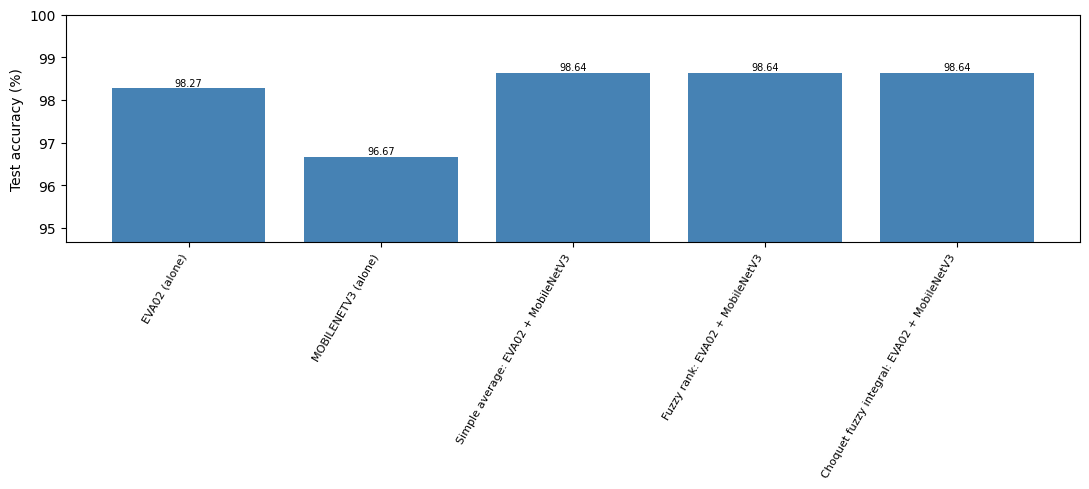

Validation accuracy of each fuzzy method:
  99.38%  Fuzzy rank: EVA02 + MobileNetV3
  99.38%  Choquet fuzzy integral: EVA02 + MobileNetV3

Best fuzzy method chosen on VAL: Fuzzy rank: EVA02 + MobileNetV3
Its test accuracy: 98.64%

                          precision    recall  f1-score   support

            Dyskeratotic     0.9939    1.0000    0.9969       163
            Koilocytotic     0.9936    0.9455    0.9689       165
             Metaplastic     0.9691    0.9874    0.9782       159
               Parabasal     1.0000    1.0000    1.0000       157
Superficial-Intermediate     0.9765    1.0000    0.9881       166

                accuracy                         0.9864       810
               macro avg     0.9866    0.9866    0.9864       810
            weighted avg     0.9866    0.9864    0.9863       810



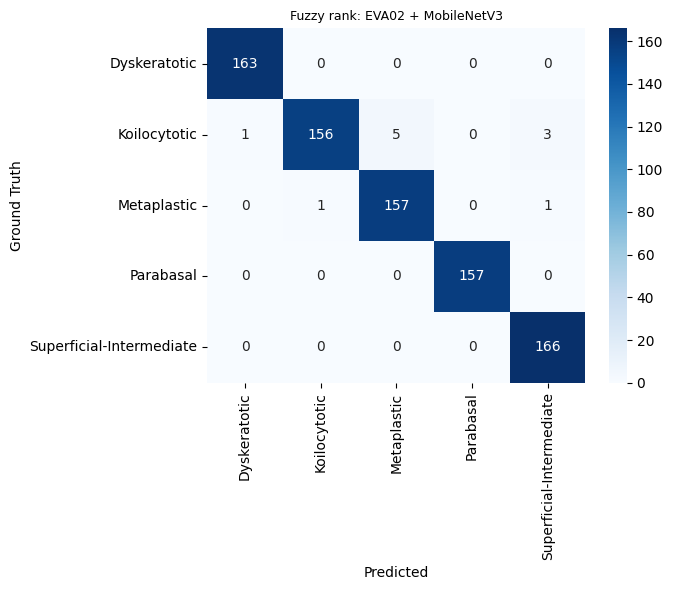

Saved to: /kaggle/working/all_probs/fuzzy_eva02_mobilenetv3


In [8]:
plt.figure(figsize=(11, 5))
plt.bar(range(len(table)), table["Test Acc (%)"], color="steelblue")
plt.xticks(range(len(table)), table["Method"], rotation=60, ha="right", fontsize=8)
plt.ylim(max(0, table["Test Acc (%)"].min() - 2), 100)
plt.ylabel("Test accuracy (%)")
for i, v in enumerate(table["Test Acc (%)"]):
    plt.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fuzzy_accuracy_bar.png"), dpi=300)
plt.show()

final_name = max(val_scores, key=val_scores.get)
final_pred = preds[final_name]
print("Validation accuracy of each fuzzy method:")
for k, v in sorted(val_scores.items(), key=lambda kv: -kv[1]):
    print(f"  {v*100:.2f}%  {k}")
print(f"\nBest fuzzy method chosen on VAL: {final_name}")
print(f"Its test accuracy: {accuracy_score(test_labels, final_pred)*100:.2f}%\n")
print(classification_report(test_labels, final_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(test_labels, final_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(final_name, fontsize=9)
plt.xlabel("Predicted")
plt.ylabel("Ground Truth")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fuzzy_confusion_matrix.png"), dpi=300)
plt.show()

print("Saved to:", OUT_DIR)